#Predicción de ventas de campañas publicitarias

## 1. Dataset de trabajo

**Usaremos un conjunto de datos de campañas digitales**. Cada fila representa una campaña/observación y contiene información de canal, región, dispositivo, visitas, inversión, conversiones, ventas y satisfacción.

> Al ser datos sintéticos, no representan resultados reales de ninguna empresa. Se construyeron únicamente con fines pedagógicos.

In [2]:
# Librerías principales.
# pandas: manipulación de datos
# numpy: operaciones numéricas
# matplotlib: visualización base de Python
# seaborn: visualizaciones estadísticas de alto nivel

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual sencilla para los gráficos.
sns.set_theme(style="whitegrid")

# Mostrar números con separadores de miles para facilitar la lectura.
pd.options.display.float_format = "{:,.2f}".format

In [3]:
# El archivo CSV debe encontrarse en la misma carpeta que este notebook.
archivo = "/content/semana5_visualizacion_datos.csv"

df = pd.read_csv(archivo)

# Observamos las primeras filas.
df.head(-1)

,id_campana,mes,canal,region,dispositivo,edad_publico,visitas,tiempo_sitio_min,inversion_publicidad_cop,conversiones,tasa_conversion,ventas_cop,satisfaccion
0,1,Enero,Email,Cali,Móvil,37,200,4.61,282255,15,0.07,2255191,3.22
1,2,Junio,Buscadores,Cali,Móvil,26,294,5.21,1139398,16,0.05,2496241,4.46
2,3,Mayo,Email,Bogotá,Móvil,31,241,6.17,612598,23,0.10,2425287,4.68
3,4,Enero,Email,Medellín,Móvil,36,40,6.82,330687,6,0.15,1078572,4.08
4,5,Mayo,Redes sociales,Medellín,Móvil,42,206,5.02,1422848,6,0.03,588762,4.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...
234,235,Abril,Referidos,Bogotá,Escritorio,30,129,4.27,234192,5,0.04,862931,3.87
235,236,Enero,Email,Bogotá,Móvil,26,302,3.44,872295,13,0.04,1373766,4.26
236,237,Febrero,Buscadores,Medellín,Móvil,41,298,7.92,1831890,27,0.09,5011973,5.00
237,238,Junio,Email,Medellín,Móvil,24,206,7.03,858559,23,0.11,4690424,5.00


## Diccionario de datos

El conjunto de datos contiene información sintética sobre **240 campañas de marketing digital** realizadas a través de diferentes canales, regiones y dispositivos. Cada fila representa una campaña y las columnas describen características del público, interacción de los usuarios, inversión publicitaria y resultados obtenidos.

| Columna | Tipo de variable | Descripción |
|---|---|---|
| `id_campana` | Identificador | Código único asignado a cada estudiante |
| `mes` | Categórica ordinal / Temporal | Mes en el que se realizó o registró la campaña. Incluye valores entre enero y junio. |
| `canal` | Categórica nominal | Canal utilizado para atraer usuarios. Puede tomar valores como **Redes sociales, Buscadores, Email o Referidos**. |
| `region` | Categórica nominal | Ciudad o región asociada con la campaña. Incluye **Bogotá, Medellín, Cali y Barranquilla**. |
| `dispositivo` | Categórica nominal | Dispositivo utilizado principalmente por los usuarios para acceder al contenido: **Móvil, Escritorio o Tablet**. |
| `edad_publico` | Numérica discreta | Edad aproximada o representativa del público asociado con la campaña, expresada en años. |
| `visitas` | Numérica discreta | Número de visitas registradas durante la campaña. |
| `tiempo_sitio_min` | Numérica continua | Tiempo promedio que los usuarios permanecen en el sitio web, expresado en minutos. |
| `inversion_publicidad_cop` | Numérica continua | Cantidad de dinero invertida en publicidad para la campaña, expresada en pesos colombianos (COP). |
| `conversiones` | Numérica discreta | Número de usuarios que realizaron la acción objetivo de la campaña, como una compra, registro o solicitud. |
| `tasa_conversion` | Numérica continua / Proporción | Proporción de visitas que terminaron en una conversión. Se calcula aproximadamente como `conversiones / visitas`. |
| `ventas_cop` | Numérica continua | Valor monetario total generado en ventas por la campaña, expresado en pesos colombianos (COP). |
| `satisfaccion` | Numérica continua / Escala | Nivel de satisfacción de los usuarios, medido aproximadamente en una escala de **1 a 5**, donde valores más altos indican mayor satisfacción. |

### Interpretación general

Cada fila del conjunto de datos puede entenderse como la respuesta a la pregunta:

> **¿Qué ocurrió en esta campaña de marketing?**

Las columnas permiten analizar aspectos como:

- el canal utilizado,
- la región donde se desarrolló la campaña,
- el dispositivo utilizado por los usuarios,
- el número de visitas,
- el tiempo de permanencia,
- la inversión realizada,
- las conversiones obtenidas,
- las ventas generadas,
- y el nivel de satisfacción.

Este conjunto de datos permite practicar la selección de diferentes métodos gráficos, como histogramas, gráficos de barras, diagramas de caja, gráficos de líneas y diagramas de dispersión.

In [4]:
# Dimensiones del conjunto de datos:
# (número de filas, número de columnas)
df.shape

(240, 13)

In [5]:
# Revisamos los tipos de datos.
# Esta información es fundamental para decidir qué gráfico tiene sentido.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_campana                240 non-null    int64  
 1   mes                       240 non-null    object 
 2   canal                     240 non-null    object 
 3   region                    240 non-null    object 
 4   dispositivo               240 non-null    object 
 5   edad_publico              240 non-null    int64  
 6   visitas                   240 non-null    int64  
 7   tiempo_sitio_min          240 non-null    float64
 8   inversion_publicidad_cop  240 non-null    int64  
 9   conversiones              240 non-null    int64  
 10  tasa_conversion           240 non-null    float64
 11  ventas_cop                240 non-null    int64  
 12  satisfaccion              240 non-null    float64
dtypes: float64(3), int64(6), object(4)
memory usage: 24.5+ KB


In [6]:
# Frecuencias de algunas variables categóricas.
for columna in ["canal", "region", "dispositivo"]:
    print(f"\n--- {columna.upper()} ---")
    print(df[columna].value_counts())


--- CANAL ---
canal
Redes sociales    92
Buscadores        72
Email             49
Referidos         27
Name: count, dtype: int64

--- REGION ---
region
Bogotá          95
Medellín        57
Cali            53
Barranquilla    35
Name: count, dtype: int64

--- DISPOSITIVO ---
dispositivo
Móvil         141
Escritorio     81
Tablet         18
Name: count, dtype: int64


### Interpretación

El gráfico de barras es apropiado porque `canal` es una variable **categórica**. La altura de cada barra representa cuántas observaciones pertenecen a cada categoría.

**Pregunta:** ¿qué canal aparece con mayor frecuencia? ¿Ese resultado significa necesariamente que sea el canal con mejores ventas? Explique.

**Rspuesta:** No necesariamente, la cantidad de campañas entendidas como "esfuerzos pulicitarios" no es equivalente al nivel de ventas

# 15. Actividad híbrida: portafolio de visualizaciones interpretadas

Para su proyecto:

1. Seleccione **tres preguntas analíticas** relevantes.
2. Para cada pregunta, elija el gráfico que mejor corresponda al tipo de variables.
3. Mejore títulos, etiquetas, escalas y legibilidad.
4. Evite elementos decorativos que no aporten información.
5. Debajo de cada gráfico escriba un hallazgo usando la estructura:
   - Hallazgo
   - Evidencia
   - Precaución
6. Incluya al menos:
   - una visualización de distribución,
   - una visualización comparativa,
   - un diagrama de dispersión.

### Entregable

Un **portafolio de tres visualizaciones interpretadas** que pueda incorporarse al proyecto de curso.

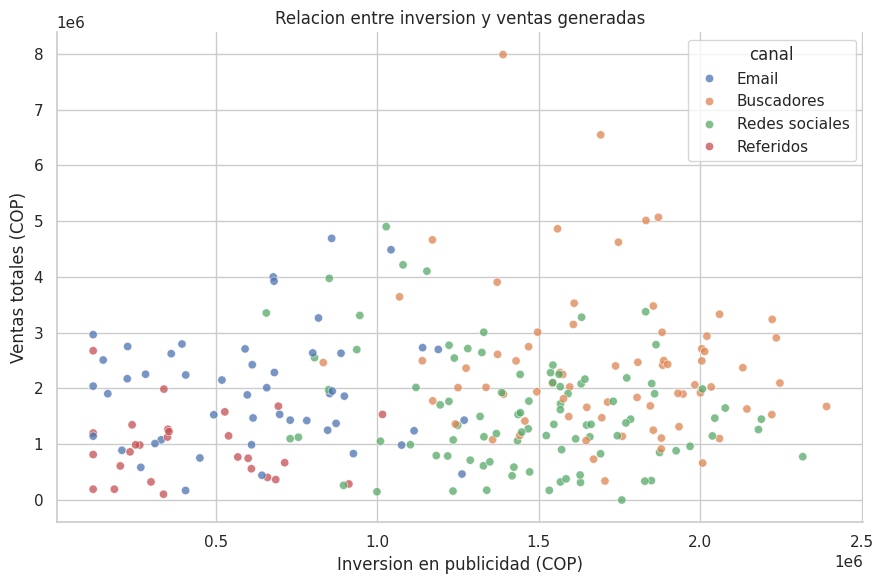

In [7]:
#Grafico 1

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="inversion_publicidad_cop",
    y="ventas_cop",               # O "tasa_conversion"
    hue="canal",                  # agrupa por color si lo necesitas
    alpha=0.75
)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.title("Relacion entre inversion y ventas generadas")
plt.xlabel("Inversion en publicidad (COP)")
plt.ylabel("Ventas totales (COP)")

plt.tight_layout()
plt.show()

Pregunta: ¿Cómo se distribuyen las ventas en relacion a la inversion y el canal?

  Hallazgo: La mayoría de las campañas generan ingresos de nivel bajo a medio
  
   Evidencia: Las campañas con mayor frecuencia se ubican entre $1,000,000 y $2,000,000. A partir de los $3,000,000 COP la cantidad de campañas cae considerablemente, observándose únicamente dos valores atípicos aislados.
   
 Precaución: Utilizar el promedio general como métrica de rendimiento puede sobreestimar las expectativas del negocio debido al impacto de los valores atípicos; es preferible tomar la mediana como referencia.   

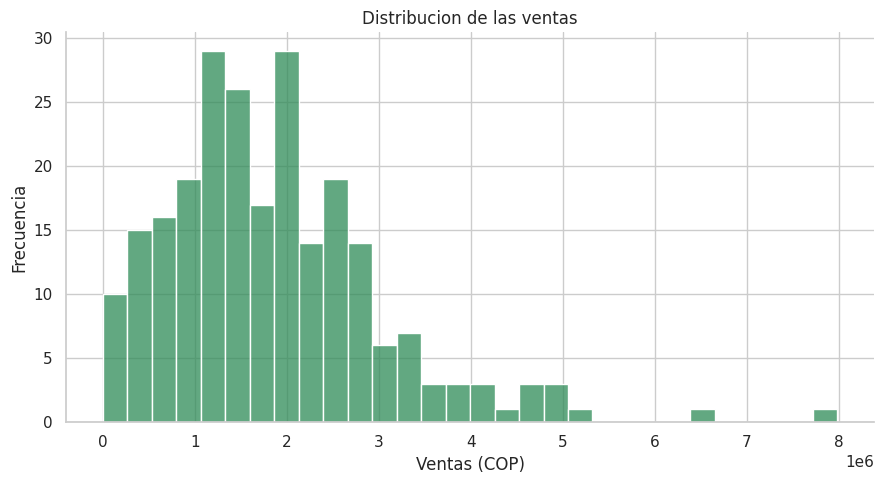

In [8]:
#Grafico 2
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="ventas_cop",
    bins=30,
    color="seagreen"
)

# Limpieza de bordes para mejor legibilidad
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.title("Distribucion de las ventas")
plt.xlabel("Ventas (COP)")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

Pregunta: ¿Cómo se relaciona la inversión publicitaria con las ventas obtenidas y de qué manera influye el canal de adquisición?

  Hallazgo: Invertir más dinero no garantiza un incremento en las ventas puesto que la eficiencia depende en gran medida del canal utilizado.  
  
   Evidencia: Canales como Email y Referidos consiguen ventas competitivas (entre $1,000,000 y $4,000,000 COP) manteniendo costos de inversión bajos . En contraste, Redes sociales y Buscadores exigen inversiones superiores (entre $1,200,000 y $2,300,000 COP) pero la mayoría de sus puntos permanecen agrupados en los mismos niveles de ventas.   
   
   Precaución: Incrementar el presupuesto en canales de alto costo como "Redes sociales" sin optimizar la conversión puede ser perjudicial.

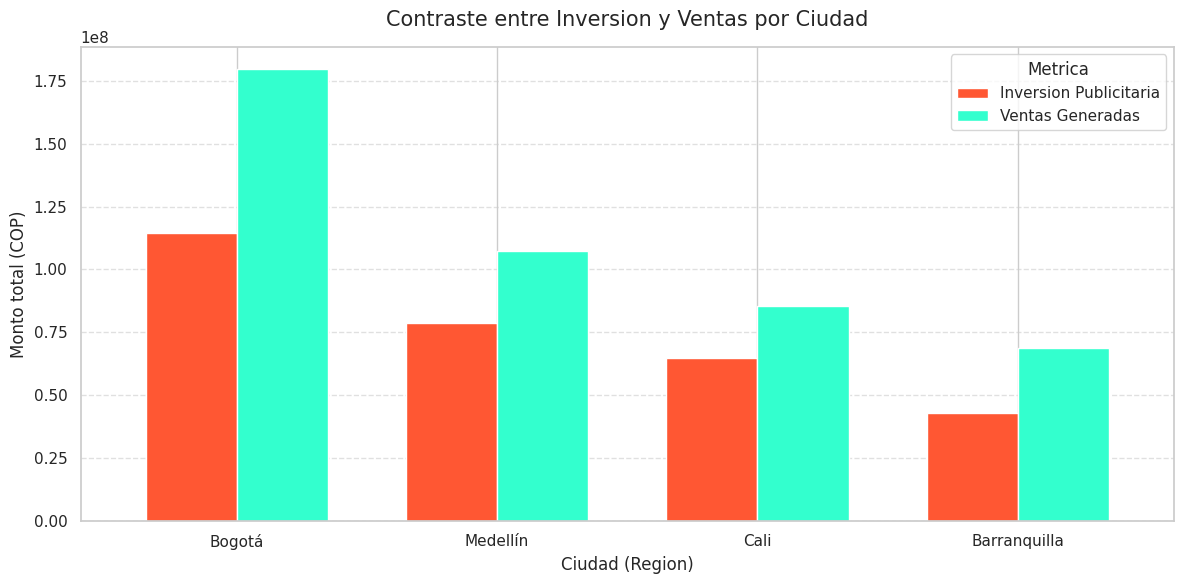

In [9]:
#Grafico 3
ciudades_iyv = df.groupby('region')[['inversion_publicidad_cop', 'ventas_cop']].sum()
ciudades_iyv = ciudades_iyv.sort_values('ventas_cop', ascending=False)

ax = ciudades_iyv.plot(kind='bar', figsize=(12, 6), color=['#FF5733', '#33FFCE'], width=0.7)

plt.title('Contraste entre Inversion y Ventas por Ciudad', fontsize=15, pad=15)
plt.xlabel('Ciudad (Region)', fontsize=12)
plt.ylabel('Monto total (COP)', fontsize=12)
plt.legend(['Inversion Publicitaria', 'Ventas Generadas'], title='Metrica', fontsize=11)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Pregunta: ¿Qué ciudades generan mayores ingresos debido a las campañas, contrastando con la inversión?  

Hallazgo: Bogotá es el mercado que genera mayor volumen de ventas y mantiene la brecha mas amplia frente a la inversión realizada.

Evidencia: Bogotá alcanza un total cercano a los 180,000,000 cop en ventas frente a una inversión publicitaria aproximada de $114,000,000.
   
Precaución: La ventaja de Bogotá en valores absolutos puede deberse simplemente a la escala de su población, por lo que no se puede asegurar que el exito ahi sea por "tener mejores campañas".



--- Regresión lineal simple: inversión -> ventas ---
Pendiente: 0.27
Intercepto: 1,498,629
R²: -0.011
MAE: 926,342 COP


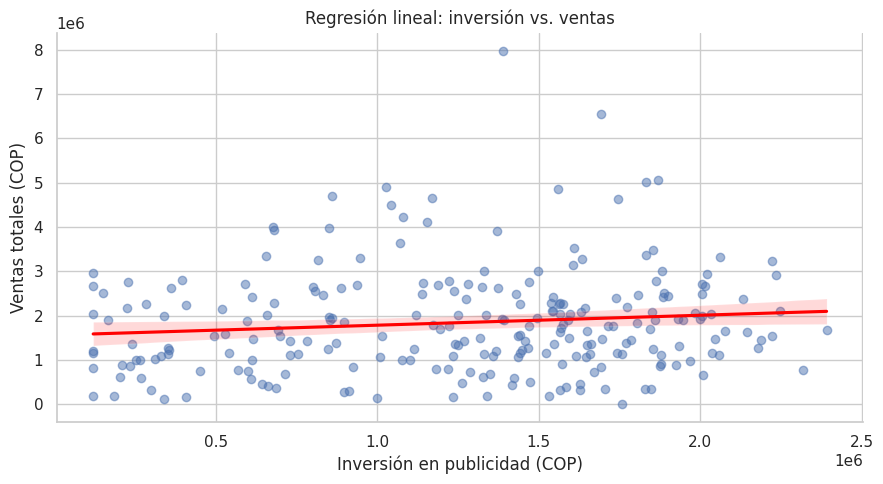

In [10]:
# ============================================================
# Regresión lineal simple: inversión -> ventas
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Variable explicativa (X) y variable a predecir (y)
X = df[["inversion_publicidad_cop"]]
y = df["ventas_cop"]

# 80% para entrenar, 20% para probar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Entrenar el modelo y predecir
modelo = LinearRegression()
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

# Resultados
print("--- Regresión lineal simple: inversión -> ventas ---")
print(f"Pendiente: {modelo.coef_[0]:.2f}")
print(f"Intercepto: {modelo.intercept_:,.0f}")
print(f"R²: {r2_score(y_test, pred):.3f}")
print(f"MAE: {mean_absolute_error(y_test, pred):,.0f} COP")

# Gráfico con la recta de regresión
plt.figure(figsize=(9, 5))
sns.regplot(data=df, x="inversion_publicidad_cop", y="ventas_cop",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.title("Regresión lineal: inversión vs. ventas")
plt.xlabel("Inversión en publicidad (COP)")
plt.ylabel("Ventas totales (COP)")
plt.tight_layout()
plt.show()

Pregunta: ¿Se puede predecir cuánto venderá una campaña a partir de su inversión publicitaria?

Hallazgo: La inversión tiene una relación positiva pero muy débil con las ventas, por lo que por sí sola sirve poco para predecir cuánto venderá una campaña.

Evidencia: La recta de regresión sube de forma muy suave: pasar de una inversión cercana a 0,1 millones a una de 2,4 millones solo eleva las ventas estimadas de aproximadamente 1,6 a 2,1 millones de COP. Además, los puntos están muy dispersos alrededor de la recta. Con la misma inversión hay campañas que venden casi 0 y otras que superan los 4 millones. El modelo obtuvo un R² de [tu R²], es decir, la inversión explica solo un [R² × 100]% de la variación en las ventas, y un error promedio (MAE) de [tu MAE] COP por predicción.

Precaución: Una relación débil no significa que invertir no sirva, sino que otros factores (el canal, la ciudad, la conversión) influyen más en las ventas, como ya mostraba el Gráfico 1. Los dos valores atípicos (cerca de 6,5 y 8 millones) pueden mover la recta hacia arriba, y el modelo extrapola mal fuera del rango observado. Por último, los datos son sintéticos, así que esta relación no describe a ninguna empresa real. Para mejorar la predicción habría que incluir más variables, como el canal y las visitas.